# 01 - Exploratory data analysis: DataCo late deliveries

**Question:** at the moment an order is placed, can we predict whether it will arrive late?

This notebook checks (1) what the label really means, (2) which columns would *leak* the answer, and (3) which order-time signals look predictive.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from shipsense.config import RAW_CSV
raw = pd.read_csv(RAW_CSV, encoding='latin1')
print(raw.shape)
raw.head(3).T.head(20)

(180519, 53)


,0,1,2
Type,DEBIT,TRANSFER,CASH
Days for shipping (real),3,5,4
Days for shipment (scheduled),4,4,4
Benefit per order,91.25,-249.089996,-247.779999
Sales per customer,314.640015,311.359985,309.720001
Delivery Status,Advance shipping,Late delivery,Shipping on time
Late_delivery_risk,0,1,0
Category Id,73,73,73
Category Name,Sporting Goods,Sporting Goods,Sporting Goods
Customer City,Caguas,Caguas,San Jose


## 1. One row = one order *item*, not one order

In [2]:
print('rows:', len(raw), '| unique orders:', raw['Order Id'].nunique())
print('orders whose items disagree on the label:',
      (raw.groupby('Order Id')['Late_delivery_risk'].nunique() > 1).sum())

rows: 180519 | unique orders: 65752
orders whose items disagree on the label: 0


Every item in an order shares the label. If we split rows randomly, items from the *same* order would sit in both train and test, inflating scores. **Decision: model at order level.**

## 2. What defines the label? (leakage check)

In [3]:
late_by_rule = (raw['Days for shipping (real)'] > raw['Days for shipment (scheduled)']).astype(int)
print('label == (real days > scheduled days):', round((late_by_rule == raw['Late_delivery_risk']).mean(), 4))
pd.crosstab(raw['Delivery Status'], raw['Late_delivery_risk'])

label == (real days > scheduled days): 0.9755


Late_delivery_risk,0,1
Delivery Status,,
Advance shipping,41592,0
Late delivery,0,98977
Shipping canceled,7754,0
Shipping on time,32196,0


`Days for shipping (real)` and `Delivery Status` basically *are* the label, and both are only known after delivery. Including them would give ~98-100% accuracy and a useless model. Shipping date and profit fields are also post-fulfilment. **All are excluded.**

In [4]:
pd.crosstab(raw['Order Status'], raw['Late_delivery_risk'])

Late_delivery_risk,0,1
Order Status,,
CANCELED,3692,0
CLOSED,8507,11109
COMPLETE,25292,34199
ON_HOLD,4354,5450
PAYMENT_REVIEW,811,1082
PENDING,8515,11712
PENDING_PAYMENT,16910,22922
PROCESSING,9399,12503
SUSPECTED_FRAUD,4062,0


Canceled and suspected-fraud orders are *always* 0 because they never ship. **Decision: drop them**; the model answers 'given it ships, will it be late?'.

## 3. Order-time signals

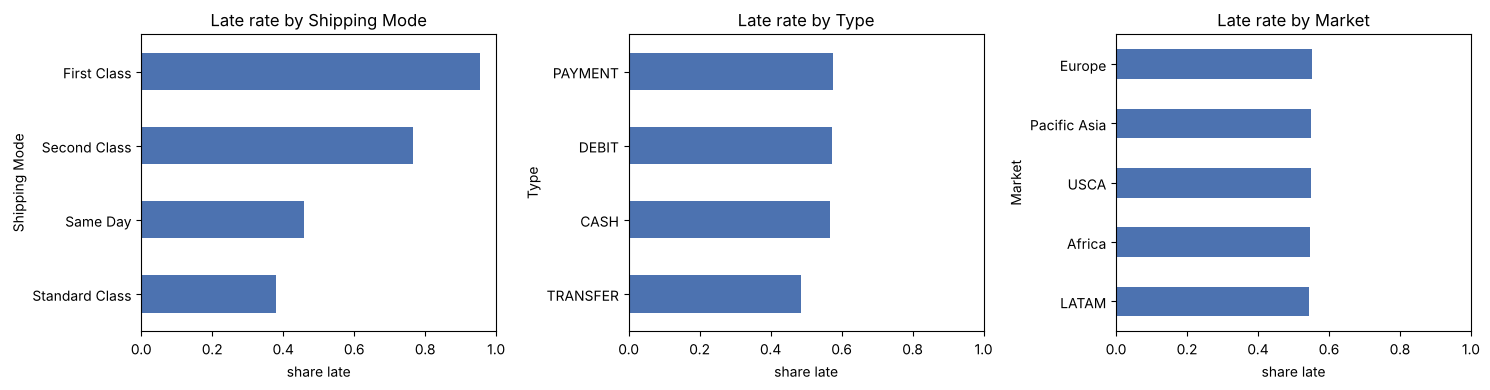

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Shipping Mode', 'Type', 'Market']):
    raw.groupby(col)['Late_delivery_risk'].mean().sort_values().plot.barh(ax=ax, color='#4C72B0')
    ax.set_title(f'Late rate by {col}'); ax.set_xlim(0, 1); ax.set_xlabel('share late')
plt.tight_layout()

**Shipping mode dominates:** First Class is late ~95% of the time (scheduled 1 day), Standard Class ~38% (scheduled 4 days). Payment type matters a little (TRANSFER is lower). Market barely matters (all ~55%).

In [6]:
pd.crosstab(raw['Shipping Mode'], raw['Days for shipping (real)'], normalize='index').round(2)

Days for shipping (real),0,1,2,3,4,5,6
Shipping Mode,,,,,,,
First Class,0.00,0.00,1.0,0.0,0.0,0.0,0.0
Same Day,0.52,0.48,0.0,0.0,0.0,0.0,0.0
Second Class,0.00,0.00,0.2,0.2,0.2,0.2,0.2
Standard Class,0.00,0.00,0.2,0.2,0.2,0.2,0.2


Striking pattern: First Class *always* takes 2 days (scheduled 1, so it is always late), and Second/Standard Class are spread evenly over 2-6 days. Within a mode, actual days look close to random, which caps how well *any* model can do. A realistic goal is beating the shipping-mode rule, not 99% accuracy. (This is a known property of the DataCo dataset - worth saying in interviews.)

Text(0, 0.5, 'share late')

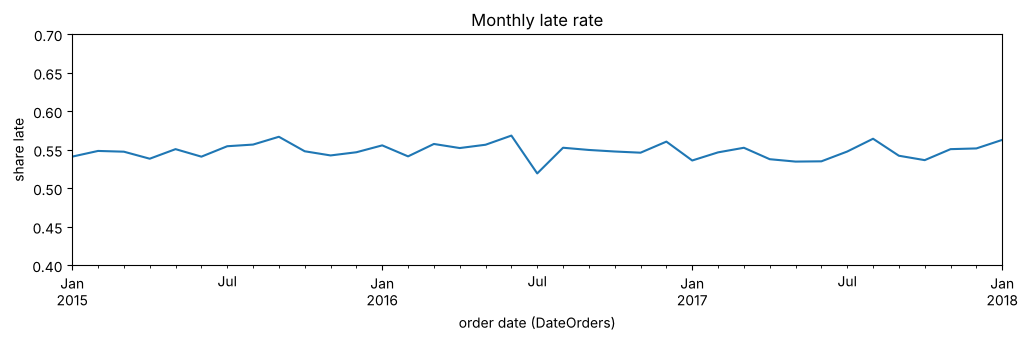

In [7]:
ts = pd.to_datetime(raw['order date (DateOrders)'])
raw.groupby(ts.dt.to_period('M'))['Late_delivery_risk'].mean().plot(figsize=(12, 3), title='Monthly late rate')
plt.ylim(0.4, 0.7); plt.ylabel('share late')

The late rate is stable over time (~54-57%), so a **time-based split** (train 2015-16, validate H1 2017, test Jul 2017-Jan 2018) is fair and mirrors production.

## 4. Feature table built in SQL
See `sql/order_features.sql`. Load it:

In [8]:
from shipsense.data import build_database, load_raw, load_order_features
build_database(load_raw())
feats = load_order_features()
print(feats.shape)
feats.head()

(62897, 19)


,order_id,order_ts,shipping_mode,days_scheduled,payment_type,market,order_region,order_country,customer_segment,n_items,total_quantity,total_sales,avg_discount_rate,n_departments,main_department,late,order_hour,order_dow,order_month
0,1,2015-01-01 00:00:00,Standard Class,4,CASH,LATAM,Central America,México,Consumer,1,1,299.980011,0.200000,1,Fan Shop,0,0,3,1
1,2,2015-01-01 00:21:00,Standard Class,4,PAYMENT,LATAM,South America,Colombia,Consumer,3,7,579.980011,0.096667,3,Golf,0,0,3,1
2,4,2015-01-01 01:03:00,Standard Class,4,CASH,LATAM,South America,Colombia,Home Office,4,14,699.850010,0.142500,4,Apparel,1,1,3,1
3,5,2015-01-01 01:24:00,Standard Class,4,DEBIT,LATAM,South America,Colombia,Consumer,5,10,1129.860039,0.136000,2,Fan Shop,1,1,3,1
4,7,2015-01-01 02:06:00,Second Class,2,DEBIT,LATAM,South America,Brasil,Consumer,3,7,579.920013,0.070000,2,Fan Shop,1,2,3,1


## Takeaways
1. Model at the order level (62,897 shipped orders).
2. Exclude post-delivery columns (they leak the label).
3. Shipping mode is the strongest signal; any model must beat a shipping-mode-only rule.
4. Use a time-based split.

Next: `python -m shipsense.train` compares the models.